1. Setup and reproducibility
We locate the repository root whether the notebook runs from the root or the notebooks/ directory, then fix random seeds.

In [1]:
from pathlib import Path
import sys
import random
import math
import numpy as np
import matplotlib.pyplot as plt

root = Path.cwd().resolve()
if not (root / "src" / "engine.py").exists():
    root = root.parent
assert (root / "src" / "engine.py").exists(), "Open notebook from the project root or notebooks/ directory"
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

from src.engine import Value
from src.nn import MLP

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
print("Project root:", root)
print("NumPy:", np.__version__)


Project root: D:\deep_learning_assignments\assignment1\assignment-1-micrograd-template
NumPy: 2.5.1


2. Dataset: two interleaving moons
We generate 80 points (40 per class) with fixed Gaussian noise, without downloading external data. Labels are mapped to −1 and +1, matching the tanh output range. The split is stratified: 30 training and 10 test points per class.

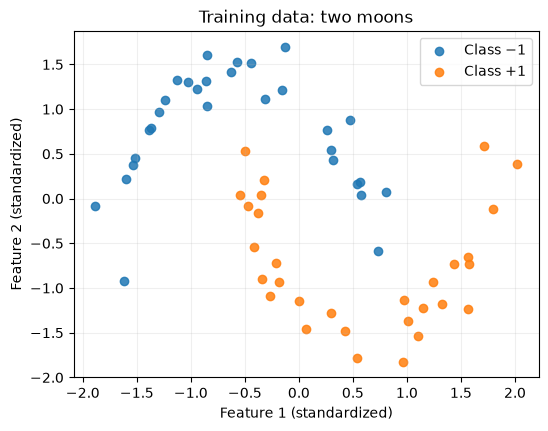

Train: 60 | Test: 20


In [2]:
n_per_class = 40
theta = np.linspace(0, np.pi, n_per_class)
noise = 0.09
upper = np.column_stack([np.cos(theta), np.sin(theta)])
lower = np.column_stack([1 - np.cos(theta), 0.5 - np.sin(theta)])
X = np.vstack([upper, lower]) + np.random.normal(0, noise, (2*n_per_class, 2))
y = np.array([-1.0]*n_per_class + [1.0]*n_per_class)

rng = np.random.default_rng(SEED)
train_idx, test_idx = [], []
for cls in (-1.0, 1.0):
    indices = rng.permutation(np.where(y == cls)[0])
    train_idx.extend(indices[:30])
    test_idx.extend(indices[30:])
train_idx = np.array(train_idx)
test_idx = np.array(test_idx)

# Normalize using training data only (prevents test-set leakage).
mean = X[train_idx].mean(axis=0)
std = X[train_idx].std(axis=0)
X = (X - mean) / std
X_train, y_train = X[train_idx], y[train_idx]
X_test, y_test = X[test_idx], y[test_idx]

fig, ax = plt.subplots(figsize=(6, 4.5))
for cls, color, label in [(-1, 'tab:blue', 'Class −1'), (1, 'tab:orange', 'Class +1')]:
    mask = y_train == cls
    ax.scatter(X_train[mask, 0], X_train[mask, 1], c=color, label=label, alpha=0.85)
ax.set(xlabel='Feature 1 (standardized)', ylabel='Feature 2 (standardized)', title='Training data: two moons')
ax.legend(); ax.grid(alpha=0.2)
plt.show()
print(f'Train: {len(X_train)} | Test: {len(X_test)}')


3. Model and objective
Architecture: 2 → 8 → 8 → 1 with tanh activations. We use mean squared error (MSE) for labels −1/+1 because the engine supports scalar arithmetic and tanh directly. This is a demonstration of binary classification using a regression-style loss, not cross-entropy.

In [3]:
random.seed(SEED)
model = MLP(2, [8, 8, 1])
print('Architecture: 2 → 8 → 8 → 1')
print('Trainable parameters:', len(model.parameters()))

def predict_scores(features):
    return [model(row.tolist()) for row in features]

def mse_loss(features, targets):
    predictions = predict_scores(features)
    return sum((pred - float(target)) ** 2 for pred, target in zip(predictions, targets)) / len(targets)

def accuracy(features, targets):
    scores = [pred.data for pred in predict_scores(features)]
    predicted = np.where(np.asarray(scores) >= 0.0, 1.0, -1.0)
    return float(np.mean(predicted == targets))

print('Initial train loss:', round(mse_loss(X_train, y_train).data, 5))
print('Initial test accuracy:', round(accuracy(X_test, y_test), 3))


Architecture: 2 → 8 → 8 → 1
Trainable parameters: 105
Initial train loss: 1.25575
Initial test accuracy: 0.55


4. Gradient descent training
For each epoch, we build a fresh computation graph, clear parameter gradients, call backward(), then update parameters using w ← w − η∂L/∂w. We use full-batch gradient descent and a fixed learning rate. No deep learning framework is used.

In [4]:
EPOCHS = 180
LR = 0.05
history = {'epoch': [], 'train_loss': [], 'train_acc': [], 'test_acc': []}

for epoch in range(1, EPOCHS + 1):
    model.zero_grad()
    loss = mse_loss(X_train, y_train)
    loss.backward()
    for p in model.parameters():
        p.data -= LR * p.grad

    if epoch == 1 or epoch % 5 == 0 or epoch == EPOCHS:
        history['epoch'].append(epoch)
        history['train_loss'].append(mse_loss(X_train, y_train).data)
        history['train_acc'].append(accuracy(X_train, y_train))
        history['test_acc'].append(accuracy(X_test, y_test))

print(f"Final train loss: {history['train_loss'][-1]:.6f}")
print(f"Final train accuracy: {history['train_acc'][-1]:.1%}")
print(f"Final test accuracy: {history['test_acc'][-1]:.1%}")
assert np.isfinite(history['train_loss']).all()
assert history['train_loss'][-1] < history['train_loss'][0], 'Training loss did not decrease'


Final train loss: 0.109926
Final train accuracy: 98.3%
Final test accuracy: 100.0%


5. Training curves
Training loss should generally decrease. Test accuracy is shown separately to illustrate generalization; it need not improve monotonically.

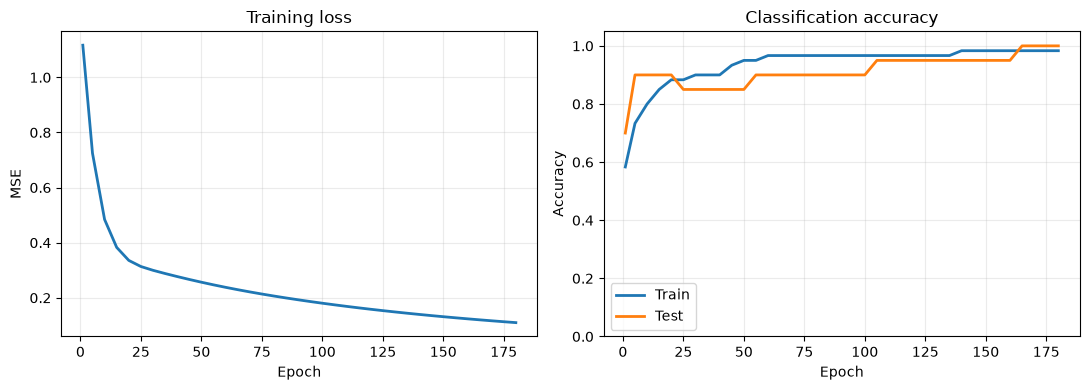

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(history['epoch'], history['train_loss'], linewidth=2)
axes[0].set(xlabel='Epoch', ylabel='MSE', title='Training loss')
axes[1].plot(history['epoch'], history['train_acc'], label='Train', linewidth=2)
axes[1].plot(history['epoch'], history['test_acc'], label='Test', linewidth=2)
axes[1].set(xlabel='Epoch', ylabel='Accuracy', title='Classification accuracy', ylim=(0, 1.05))
axes[1].legend()
for ax in axes: ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()


6. Decision boundary and test predictions
A positive score predicts class +1; a negative score predicts class −1. The decision boundary is the set of points where the model score is approximately zero.

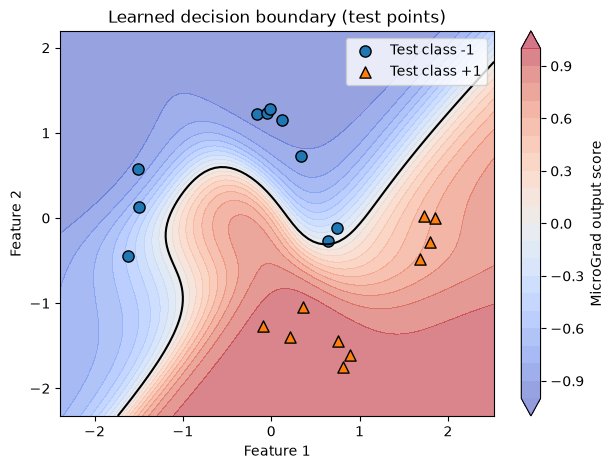

Sample 00 | target=-1 | score=-0.9358 | prediction=-1
Sample 01 | target=-1 | score=-0.5813 | prediction=-1
Sample 02 | target=-1 | score=-0.9406 | prediction=-1
Sample 03 | target=-1 | score=-0.9444 | prediction=-1
Sample 04 | target=-1 | score=-0.4738 | prediction=-1
Sample 05 | target=-1 | score=-0.0521 | prediction=-1
Sample 06 | target=-1 | score=-0.8584 | prediction=-1
Sample 07 | target=-1 | score=-0.2069 | prediction=-1


In [6]:
all_x = np.vstack([X_train, X_test])
xmin, ymin = all_x.min(axis=0) - 0.5
xmax, ymax = all_x.max(axis=0) + 0.5
xx, yy = np.meshgrid(np.linspace(xmin, xmax, 85), np.linspace(ymin, ymax, 85))
mesh = np.column_stack([xx.ravel(), yy.ravel()])
zz = np.array([model(point.tolist()).data for point in mesh]).reshape(xx.shape)

fig, ax = plt.subplots(figsize=(7, 5))
contour = ax.contourf(xx, yy, zz, levels=np.linspace(-1, 1, 21), cmap='coolwarm', alpha=0.55, extend='both')
ax.contour(xx, yy, zz, levels=[0], colors='black', linewidths=1.5)
for cls, marker in [(-1, 'o'), (1, '^')]:
    mask = y_test == cls
    ax.scatter(X_test[mask, 0], X_test[mask, 1], marker=marker, edgecolor='black', s=65, label=f'Test class {int(cls):+d}')
ax.set(xlabel='Feature 1', ylabel='Feature 2', title='Learned decision boundary (test points)')
ax.legend()
fig.colorbar(contour, ax=ax, label='MicroGrad output score')
plt.show()

scores = np.array([model(row.tolist()).data for row in X_test])
for i in range(min(8, len(y_test))):
    print(f'Sample {i:02d} | target={int(y_test[i]):+d} | score={scores[i]:+.4f} | prediction={1 if scores[i]>=0 else -1:+d}')


7. Gradient checking on the trained MLP
For a selected parameter, compare MicroGrad’s analytical derivative with the central finite-difference estimate: [L(w+h) − L(w−h)] / (2h). We restore the parameter after each perturbation. This checks the chain rule through the whole network.

In [7]:
model.zero_grad()
loss = mse_loss(X_train[:5], y_train[:5])
loss.backward()
params = model.parameters()
h = 1e-5
checks = []
for index in [0, len(params)//2, len(params)-1]:
    p = params[index]
    analytical = p.grad
    original = p.data
    try:
        p.data = original + h
        plus = mse_loss(X_train[:5], y_train[:5]).data
        p.data = original - h
        minus = mse_loss(X_train[:5], y_train[:5]).data
    finally:
        p.data = original
    numerical = (plus - minus) / (2*h)
    abs_error = abs(analytical - numerical)
    checks.append(abs_error)
    print(f'Parameter {index:3d} | analytical={analytical:+.8f} | numerical={numerical:+.8f} | abs error={abs_error:.2e}')
assert max(checks) < 1e-4, 'Gradient check failed'
print('Gradient checks passed.')


Parameter   0 | analytical=+0.18698710 | numerical=+0.18698710 | abs error=1.18e-10
Parameter  52 | analytical=+0.13510200 | numerical=+0.13510200 | abs error=5.69e-12
Parameter 104 | analytical=+0.29040594 | numerical=+0.29040594 | abs error=3.34e-11
Gradient checks passed.


8. Conclusions and limitations
- The Value engine builds scalar computation graphs and computes gradients via reverse topological traversal.
- The MLP is trained entirely with custom scalar automatic differentiation and gradient descent.
- Numerical gradient checks provide an independent local validation of backpropagation.
- This synthetic dataset is deliberately small: scalar graphs are slower and less memory-efficient than tensor frameworks.
- The test split is held out from parameter updates, but we inspect test accuracy during training; for model selection in a larger study, use a separate validation split.
- The final results depend on the displayed seed, architecture, optimizer settings, and runtime environment.